# **BODY TYPE PREDICTING MODEL**

#### **IMPORT**

In [1]:
# -- Data --
import pandas as pd
import numpy as np

# -- Visualization --
import matplotlib.pyplot as plt
import seaborn as sns

# -- Preprocessing --
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# -- Clustering --
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# -- Save/Load --
import joblib

# - Supress warnings
import warnings
warnings.filterwarnings('ignore')
print("All imports successful.")

All imports successful.


#### **DATA COLLECTION**

In [ ]:
# collecting raw data.

df_raw = pd.read_csv("data/nhanes_bmx_data.csv")

print("data collected!")
df_raw.shape

data collected!


(66018, 50)

#### **DATA CLEANING**

In [3]:
# copy raw data to other variable to preserve the raw data as is.

df_clean = df_raw.copy()

In [4]:
# Shawcasing basic structure of data.

print("df shape:", df_clean.shape)
df_duplicates = df_clean.duplicated().sum()
print("df duplicate values:", df_duplicates)
missing_summary = df_clean.isnull().sum().sort_values(ascending=False)
missing_pct = (missing_summary / len(df_clean) * 100).round(1)

print("Missing Values by column: ")
print(pd.DataFrame({
    'Missing': missing_summary,
    'Percent': missing_pct
}).head(21))

df shape: (66018, 50)
df duplicate values: 0
Missing Values by column: 
          Missing  Percent
BMAUPREL    66018    100.0
BMAUPLEL    66018    100.0
BMALLKNE    66017    100.0
BMAUREXT    66015    100.0
BMAULEXT    66015    100.0
BMALOREX    66015    100.0
BMALORKN    66015    100.0
BMALLEXT    66015    100.0
BMIHEAD     66014    100.0
BMAEXCMT    65880     99.8
BMIRECUM    65778     99.6
BMICALF     65677     99.5
BMITHICR    65448     99.1
BMIHIP      65387     99.0
BMIHT       64939     98.4
BMXSAD3     64909     98.3
BMXSAD4     64909     98.3
BMDSADCM    64603     97.9
BMITRI      64597     97.8
BMXHEAD     64511     97.7
BMIARML     63730     96.5


In [5]:
# Seeing first 11 values (0 - 10).

df_clean.head(11)

,Unnamed: 0,BMIARMC,BMIARML,BMIHEAD,BMIHT,BMILEG,BMIRECUM,BMIWAIST,BMIWT,BMXARMC,...,BMDSTATS,BMDBMIC,BMXSAD1,BMXSAD2,BMXSAD3,BMXSAD4,BMDAVSAD,BMDSADCM,BMXHIP,BMIHIP
0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,15.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,29.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Mapping columns with new understandable names.

column_map = {
    # ---- ID & Meta ----
    "SEQN": "Respondent_ID",
    "cycle": "Survey_Cycle",

    # ---- Anthropometric Exam Status ----
    "BMDSTATS": "BodyMeasures_Status",
    "BMAEXLEN": "Exam_Length_Minutes",
    "BMAEXSTS": "Exam_Status",
    "BMAEXCMT": "Exam_Comment",

    # ---- Weight ----
    "BMXWT": "Weight_kg",
    "BMIWT": "Weight_Comment",

    # ---- Height / Length ----
    "BMXHT": "Height_cm",
    "BMIHT": "Height_Comment",
    "BMXRECUM": "Recumbent_Length_cm",
    "BMIRECUM": "RecumbentLength_Comment",

    # ---- Head ----
    "BMXHEAD": "Head_Circumference_cm",
    "BMIHEAD": "HeadCircumference_Comment",

    # ---- BMI ----
    "BMXBMI": "BMI_kg_m2",
    "BMDBMIC": "BMI_Category_Children",

    # ---- Waist & Hip ----
    "BMXWAIST": "Waist_Circumference_cm",
    "BMIWAIST": "WaistCircumference_Comment",
    "BMXHIP": "Hip_Circumference_cm",
    "BMIHIP": "HipCircumference_Comment",

    # ---- Arm ----
    "BMXARMC": "Arm_Circumference_cm",
    "BMIARMC": "ArmCircumference_Comment",
    "BMXARML": "Arm_Length_cm",
    "BMIARML": "ArmLength_Comment",

    # ---- Leg / Calf / Thigh ----
    "BMXLEG": "UpperLeg_Length_cm",
    "BMILEG": "UpperLegLength_Comment",
    "BMXCALF": "Calf_Circumference_cm",
    "BMICALF": "CalfCircumference_Comment",
    "BMXTHICR": "Thigh_Circumference_cm",
    "BMITHICR": "ThighCircumference_Comment",

    # ---- Skinfolds ----
    "BMXTRI": "Triceps_Skinfold_mm",
    "BMITRI": "TricepsSkinfold_Comment",
    "BMXSUB": "Subscapular_Skinfold_mm",
    "BMISUB": "SubscapularSkinfold_Comment",

    # ---- Sagittal Abdominal Diameter ----
    "BMXSAD1": "SAD_Reading1_cm",
    "BMXSAD2": "SAD_Reading2_cm",
    "BMXSAD3": "SAD_Reading3_cm",
    "BMXSAD4": "SAD_Reading4_cm",
    "BMDAVSAD": "SAD_Average_cm",
    "BMDSADCM": "SAD_Comment",

    # ---- Blood Pressure (Arm) ----
    "BMAAMP": "BP_Arm_Selection",
    "BMAUREXT": "BP_UpperRight_Exclusion",
    "BMAUPREL": "BP_UpperRight_Preferred",
    "BMAULEXT": "BP_UpperLeft_Exclusion",
    "BMAUPLEL": "BP_UpperLeft_Preferred",

    # ---- Blood Pressure (Leg) ----
    "BMALOREX": "BP_LowerRight_Exclusion",
    "BMALORKN": "BP_LowerRight_Knee",
    "BMALLEXT": "BP_LowerLeft_Exclusion",
    "BMALLKNE": "BP_LowerLeft_Knee",
}

# renaming the columns.

df_clean = df_clean.rename(columns= column_map)

In [7]:
# ============================================================
# Columns to DROP (no biological signal for clustering/analysis)
# ============================================================

# 1. Comment / flag codes (administrative — "could not obtain", "clothing worn", etc.)
comment_cols = [
    "Weight_Comment", "Height_Comment", "HeadCircumference_Comment",
    "RecumbentLength_Comment", "WaistCircumference_Comment",
    "ArmCircumference_Comment", "ArmLength_Comment",
    "UpperLegLength_Comment", "CalfCircumference_Comment",
    "ThighCircumference_Comment", "TricepsSkinfold_Comment",
    "SubscapularSkinfold_Comment", "HipCircumference_Comment",
]

# 2. Exam status / admin metadata.
admin_cols = [
    "BodyMeasures_Status", "Exam_Status", "Exam_Comment", "Exam_Length_Minutes",
    "SAD_Comment",
]

# 3. Blood pressure arm/leg selection (not body measures).
bp_cols = [
    "BP_Arm_Selection", "BP_UpperRight_Exclusion", "BP_UpperRight_Preferred",
    "BP_UpperLeft_Exclusion", "BP_UpperLeft_Preferred",
    "BP_LowerRight_Exclusion", "BP_LowerRight_Knee",
    "BP_LowerLeft_Exclusion", "BP_LowerLeft_Knee",
]

# 4. Redundant raw SAD readings (keep only BMDAVSAD)
sad_raw_cols = ["SAD_Reading1_cm", "SAD_Reading2_cm", "SAD_Reading3_cm", "SAD_Reading4_cm"]

# 5. ID column (not a feature)
id_cols = ["Unnamed: 0", "Respondent_ID"]

# ---- Combine all ----
cols_to_drop = comment_cols + admin_cols + bp_cols + sad_raw_cols + id_cols

# ============================================================
# Apply the drop (only drop columns that actually exist)
# ============================================================
existing_drops = [c for c in cols_to_drop if c in df_clean.columns]
df_clean = df_clean.drop(columns=existing_drops)

print(f"Dropped {len(existing_drops)} columns")
print(f"Remaining columns ({len(df_clean.columns)}):")
print(list(df_clean.columns))

Dropped 33 columns
Remaining columns (17):
['Arm_Circumference_cm', 'Arm_Length_cm', 'BMI_kg_m2', 'Head_Circumference_cm', 'Height_cm', 'UpperLeg_Length_cm', 'Recumbent_Length_cm', 'Waist_Circumference_cm', 'Weight_kg', 'Survey_Cycle', 'Calf_Circumference_cm', 'Thigh_Circumference_cm', 'Triceps_Skinfold_mm', 'Subscapular_Skinfold_mm', 'BMI_Category_Children', 'SAD_Average_cm', 'Hip_Circumference_cm']


In [8]:
# showing final columns.

df_clean.columns.tolist()

['Arm_Circumference_cm',
 'Arm_Length_cm',
 'BMI_kg_m2',
 'Head_Circumference_cm',
 'Height_cm',
 'UpperLeg_Length_cm',
 'Recumbent_Length_cm',
 'Waist_Circumference_cm',
 'Weight_kg',
 'Survey_Cycle',
 'Calf_Circumference_cm',
 'Thigh_Circumference_cm',
 'Triceps_Skinfold_mm',
 'Subscapular_Skinfold_mm',
 'BMI_Category_Children',
 'SAD_Average_cm',
 'Hip_Circumference_cm']

#### **HANDELING MISSING VALUES**

In [9]:
# copying cleaned df to another variable to remain it preserved.

df2 = df_clean.copy()

In [10]:
# Seeing basic structure of data.

print("df shape:", df2.shape)
df_duplicates = df2.duplicated().sum()
print("df duplicate values:", df_duplicates)

df shape: (66018, 17)


df duplicate values: 565


In [11]:
# Information of data.

df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66018 entries, 0 to 66017
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Arm_Circumference_cm     62691 non-null  float64
 1   Arm_Length_cm            62707 non-null  float64
 2   BMI_kg_m2                60361 non-null  float64
 3   Head_Circumference_cm    1507 non-null   float64
 4   Height_cm                60793 non-null  float64
 5   UpperLeg_Length_cm       50576 non-null  float64
 6   Recumbent_Length_cm      6998 non-null   float64
 7   Waist_Circumference_cm   58309 non-null  float64
 8   Weight_kg                64767 non-null  float64
 9   Survey_Cycle             66018 non-null  object 
 10  Calf_Circumference_cm    15239 non-null  float64
 11  Thigh_Circumference_cm   15002 non-null  float64
 12  Triceps_Skinfold_mm      18000 non-null  float64
 13  Subscapular_Skinfold_mm  16503 non-null  float64
 14  BMI_Category_Children 

In [12]:
missing_pct = (df2.isnull().mean() * 100).sort_values(ascending= False)
print("Missing % by column:")
print(missing_pct.round(2))

Missing % by column:
Head_Circumference_cm      97.72
Recumbent_Length_cm        89.40
BMI_Category_Children      80.75
Hip_Circumference_cm       80.59
Thigh_Circumference_cm     77.28
Calf_Circumference_cm      76.92
Subscapular_Skinfold_mm    75.00
Triceps_Skinfold_mm        72.73
SAD_Average_cm             68.20
UpperLeg_Length_cm         23.39
Waist_Circumference_cm     11.68
BMI_kg_m2                   8.57
Height_cm                   7.91
Arm_Circumference_cm        5.04
Arm_Length_cm               5.02
Weight_kg                   1.89
Survey_Cycle                0.00
dtype: float64


In [13]:
# Dropping columns that have missing values more than 50%.

threshold = 50
cols_to_drop = missing_pct[missing_pct > threshold].index.tolist()

print("Dropping columns (>50% missing)")
for c in cols_to_drop:
    print(f" {c}: {missing_pct[c]:.2f}%")

df_clean = df2.drop(columns= cols_to_drop)

print("\nShape after column drop:", df_clean.shape)
print("Remaining columns:", df_clean.columns.tolist())

Dropping columns (>50% missing)
 Head_Circumference_cm: 97.72%
 Recumbent_Length_cm: 89.40%
 BMI_Category_Children: 80.75%
 Hip_Circumference_cm: 80.59%
 Thigh_Circumference_cm: 77.28%
 Calf_Circumference_cm: 76.92%
 Subscapular_Skinfold_mm: 75.00%
 Triceps_Skinfold_mm: 72.73%
 SAD_Average_cm: 68.20%

Shape after column drop: (66018, 8)
Remaining columns: ['Arm_Circumference_cm', 'Arm_Length_cm', 'BMI_kg_m2', 'Height_cm', 'UpperLeg_Length_cm', 'Waist_Circumference_cm', 'Weight_kg', 'Survey_Cycle']


In [14]:
# Missing columns with missing values.

df_clean.isnull().sum()

Arm_Circumference_cm       3327
Arm_Length_cm              3311
BMI_kg_m2                  5657
Height_cm                  5225
UpperLeg_Length_cm        15442
Waist_Circumference_cm     7709
Weight_kg                  1251
Survey_Cycle                  0
dtype: int64

In [15]:
# First 10 rows of data.

df_clean.head(11)

,Arm_Circumference_cm,Arm_Length_cm,BMI_kg_m2,Height_cm,UpperLeg_Length_cm,Waist_Circumference_cm,Weight_kg,Survey_Cycle
0,15.2,18.6,14.90,91.6,NaN,45.7,12.5,1999_2000
1,29.8,38.2,24.90,174.0,NaN,98.0,75.4,1999_2000
2,19.7,25.5,17.63,136.6,34.1,64.7,32.9,1999_2000
3,16.4,20.4,NaN,NaN,NaN,NaN,13.3,1999_2000
4,35.8,39.7,29.10,178.3,45.2,99.9,92.5,1999_2000
5,26.0,34.5,22.56,162.0,39.7,81.6,59.2,1999_2000
6,31.7,38.1,29.39,162.9,43.0,90.7,78.0,1999_2000
7,20.1,36.7,15.51,162.0,41.6,64.1,40.7,1999_2000
8,22.1,32.0,18.48,156.9,42.2,64.6,45.5,1999_2000
9,37.6,43.0,30.94,190.1,46.6,108.0,111.8,1999_2000


In [16]:
# Information of data.

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66018 entries, 0 to 66017
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Arm_Circumference_cm    62691 non-null  float64
 1   Arm_Length_cm           62707 non-null  float64
 2   BMI_kg_m2               60361 non-null  float64
 3   Height_cm               60793 non-null  float64
 4   UpperLeg_Length_cm      50576 non-null  float64
 5   Waist_Circumference_cm  58309 non-null  float64
 6   Weight_kg               64767 non-null  float64
 7   Survey_Cycle            66018 non-null  object 
dtypes: float64(7), object(1)
memory usage: 4.0+ MB


#### **KNN IMPUTATION**

In [17]:
# selecting numeric only columns.

numeric_cols = df_clean.select_dtypes(include='number').columns
df_numeric = df_clean[numeric_cols].copy()

In [18]:
# using standard scaler to standardize data values.

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clean[numeric_cols])

In [19]:
# making imputer to imputate data.

imputer = KNNImputer(n_neighbors= 5) # uses 5 closest row.

df_imputed_scaled = imputer.fit_transform(df_scaled)

df_imputed = pd.DataFrame(
    scaler.inverse_transform(df_imputed_scaled),
    columns= numeric_cols
)

In [20]:
# Verifying that values are filled or not.

print("Missing after KNN: ", df_imputed.isnull().sum().sum())
print("Shape:", df_imputed.shape)

Missing after KNN:  0
Shape: (66018, 7)


In [21]:
print("--- Original data stats ---")
print(df_clean[['Height_cm', 'Weight_kg', 'BMI_kg_m2']].describe().round(2))

print("\n--- After KNN imputation ---")
print(df_imputed[['Height_cm', 'Weight_kg', 'BMI_kg_m2']].describe().round(2))

--- Original data stats ---
       Height_cm  Weight_kg  BMI_kg_m2
count   60793.00   64767.00   60361.00
mean      156.44      63.12      25.76
std        22.65      31.54       7.78
min        78.30       2.70       7.99
25%       150.90      41.50      19.90
50%       162.10      65.80      24.97
75%       171.20      83.40      30.10
max       204.50     248.20      86.20

--- After KNN imputation ---
       Height_cm  Weight_kg  BMI_kg_m2
count   66018.00   66018.00   66018.00
mean      151.75      63.05      25.07
std        28.15      31.41       7.92
min        78.30       2.70       7.99
25%       145.00      41.80      18.70
50%       160.70      65.40      24.40
75%       170.40      83.20      29.60
max       204.50     248.20      86.20


In [22]:
# removing data related to childrens and newborns

before = df_imputed.shape[0]

df_adults = df_imputed[
    (df_imputed['Height_cm'] >= 130) &
    (df_imputed['Weight_kg'] >= 30)
].copy()

after = df_adults.shape[0]

print(f"Removed {before - after} rows (likely children)")
print("Shape:", df_adults.shape)

Removed 13674 rows (likely children)
Shape: (52344, 7)


In [23]:
print(df_adults[['Height_cm', 'Weight_kg', 'BMI_kg_m2']].describe().round(2))

       Height_cm  Weight_kg  BMI_kg_m2
count   52344.00   52344.00   52344.00
mean      164.49      75.03      27.43
std        11.57      23.17       7.15
min       130.00      30.00      12.90
25%       156.80      59.40      22.40
50%       164.60      72.40      26.30
75%       172.60      88.00      31.10
max       204.50     248.20      86.20


#### **DATA QUALITY CHECK + OUTLIER REMOVAL**

In [24]:
# ─────────────────────────────────────────────────
# STEP 1: DIAGNOSE — Check for inconsistent BMI records
# ─────────────────────────────────────────────────
print("── STEP 1: DIAGNOSE ──")

df_adults['BMI_check'] = df_adults['Weight_kg'] / (df_adults['Height_cm'] / 100) ** 2
df_adults['BMI_diff'] = abs(df_adults['BMI_kg_m2'] - df_adults['BMI_check'])

print("\nBMI mismatch distribution:")
print(df_adults['BMI_diff'].describe().round(2))

print("\nRows with BMI_diff > 5: ", (df_adults['BMI_diff'] > 5).sum())
print("Rows with BMI_diff > 10:", (df_adults['BMI_diff'] > 10).sum())

# ─────────────────────────────────────────────────
# STEP 2: CLEAN — Remove inconsistent + impossible rows
# ─────────────────────────────────────────────────
print("\n── STEP 2: CLEAN ──")
before = df_adults.shape[0]

# Remove rows where recorded BMI doesn't match computed BMI
df_adults = df_adults[df_adults['BMI_diff'] <= 5]

# Remove physically impossible values
df_adults = df_adults[
    (df_adults['Height_cm'].between(130, 220)) &
    (df_adults['Weight_kg'].between(30, 300)) &
    (df_adults['BMI_kg_m2'].between(10, 80))
]

# Drop temporary columns
df_adults = df_adults.drop(columns=['BMI_check', 'BMI_diff'])

after = df_adults.shape[0]
print(f"Removed {before - after} rows")
print("Final shape:", df_adults.shape)

── STEP 1: DIAGNOSE ──

BMI mismatch distribution:
count    52344.00
mean         0.03
std          0.27
min          0.00
25%          0.00
50%          0.02
75%          0.03
max         13.60
Name: BMI_diff, dtype: float64

Rows with BMI_diff > 5:  36
Rows with BMI_diff > 10: 8

── STEP 2: CLEAN ──
Removed 41 rows
Final shape: (52303, 7)


In [25]:
# ─────────────────────────────────────────────────
# STEP 3: VERIFY — New distributions
# ─────────────────────────────────────────────────
print("\n── STEP 3: VERIFY ──")
print("\nFinal distributions:")
print(df_adults[['Height_cm', 'Weight_kg', 'BMI_kg_m2']].describe().round(2))

print("\nMissing values:", df_adults.isnull().sum().sum())
print("Duplicates:", df_adults.duplicated().sum())


── STEP 3: VERIFY ──

Final distributions:
       Height_cm  Weight_kg  BMI_kg_m2
count   52303.00   52303.00   52303.00
mean      164.49      75.01      27.43
std        11.58      23.13       7.13
min       130.00      30.00      12.90
25%       156.80      59.40      22.40
50%       164.60      72.40      26.30
75%       172.60      88.00      31.10
max       204.50     248.20      77.50

Missing values: 0
Duplicates: 698


In [26]:
# dropping duplicates.

df_adults= df_adults.drop_duplicates()
print("After dropping duplicates:")
df_adults.duplicated().sum()

After dropping duplicates:


np.int64(0)

#### **CORRELATIONS**

In [27]:
# ─────────────────────────────────────────────────
# STEP 1: Drop duplicates first
# ─────────────────────────────────────────────────
print("── CLEANING ──")
before = df_adults.shape[0]
df_adults = df_adults.drop_duplicates()
after = df_adults.shape[0]
print(f"Dropped {before - after} duplicate rows")
print(f"Final shape: {df_adults.shape}\n")

── CLEANING ──
Dropped 0 duplicate rows
Final shape: (51605, 7)



In [28]:
# ─────────────────────────────────────────────────
# STEP 2: Build correlation matrix
# ─────────────────────────────────────────────────
corr_matrix = df_adults.corr(numeric_only=True)
print("── CORRELATION MATRIX ──")
print(corr_matrix.round(3))

── CORRELATION MATRIX ──
                        Arm_Circumference_cm  Arm_Length_cm  BMI_kg_m2  \
Arm_Circumference_cm                   1.000          0.571      0.891   
Arm_Length_cm                          0.571          1.000      0.376   
BMI_kg_m2                              0.891          0.376      1.000   
Height_cm                              0.408          0.844      0.164   
UpperLeg_Length_cm                     0.249          0.654      0.037   
Waist_Circumference_cm                 0.867          0.523      0.909   
Weight_kg                              0.914          0.670      0.899   

                        Height_cm  UpperLeg_Length_cm  Waist_Circumference_cm  \
Arm_Circumference_cm        0.408               0.249                   0.867   
Arm_Length_cm               0.844               0.654                   0.523   
BMI_kg_m2                   0.164               0.037                   0.909   
Height_cm                   1.000               0.770     

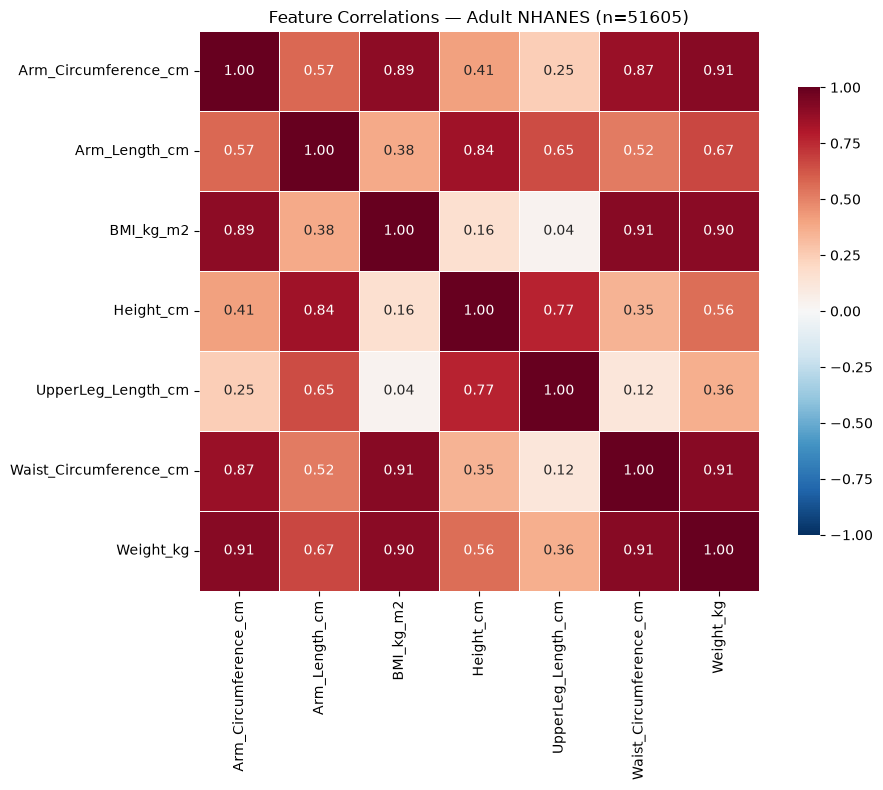

In [29]:
# ─────────────────────────────────────────────────
# STEP 3: Heatmap
# ─────────────────────────────────────────────────
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title(f'Feature Correlations — Adult NHANES (n={len(df_adults)})')
plt.tight_layout()
plt.show()

In [30]:
# ─────────────────────────────────────────────────
# STEP 4: Correlations with BMI
# ─────────────────────────────────────────────────
print("\n── CORRELATIONS WITH BMI ──")
bmi_corr = (
    corr_matrix['BMI_kg_m2']
    .drop('BMI_kg_m2')
    .sort_values(key=abs, ascending=False)
)
print(bmi_corr.round(4))


── CORRELATIONS WITH BMI ──
Waist_Circumference_cm    0.9089
Weight_kg                 0.8989
Arm_Circumference_cm      0.8908
Arm_Length_cm             0.3762
Height_cm                 0.1639
UpperLeg_Length_cm        0.0375
Name: BMI_kg_m2, dtype: float64


In [31]:
# ─────────────────────────────────────────────────
# STEP 5: Correlations with Weight
# ─────────────────────────────────────────────────
print("\n── CORRELATIONS WITH WEIGHT ──")
weight_corr = (
    corr_matrix['Weight_kg']
    .drop('Weight_kg')
    .sort_values(key=abs, ascending=False)
)
print(weight_corr.round(4))


── CORRELATIONS WITH WEIGHT ──
Arm_Circumference_cm      0.9137
Waist_Circumference_cm    0.9066
BMI_kg_m2                 0.8989
Arm_Length_cm             0.6700
Height_cm                 0.5618
UpperLeg_Length_cm        0.3642
Name: Weight_kg, dtype: float64


In [32]:
# ─────────────────────────────────────────────────
# STEP 6: High-correlation pairs (redundant features)
# ─────────────────────────────────────────────────
print("\n── HIGH-CORRELATION PAIRS (|corr| > 0.85) ──")
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.85:
            high_corr_pairs.append(
                (corr_matrix.columns[i], corr_matrix.columns[j], val)
            )

if high_corr_pairs:
    for a, b, v in high_corr_pairs:
        print(f"  {a}  ↔  {b}:  {v:.3f}")
else:
    print("  None found")


── HIGH-CORRELATION PAIRS (|corr| > 0.85) ──
  Arm_Circumference_cm  ↔  BMI_kg_m2:  0.891
  Arm_Circumference_cm  ↔  Waist_Circumference_cm:  0.867
  Arm_Circumference_cm  ↔  Weight_kg:  0.914
  BMI_kg_m2  ↔  Waist_Circumference_cm:  0.909
  BMI_kg_m2  ↔  Weight_kg:  0.899
  Waist_Circumference_cm  ↔  Weight_kg:  0.907


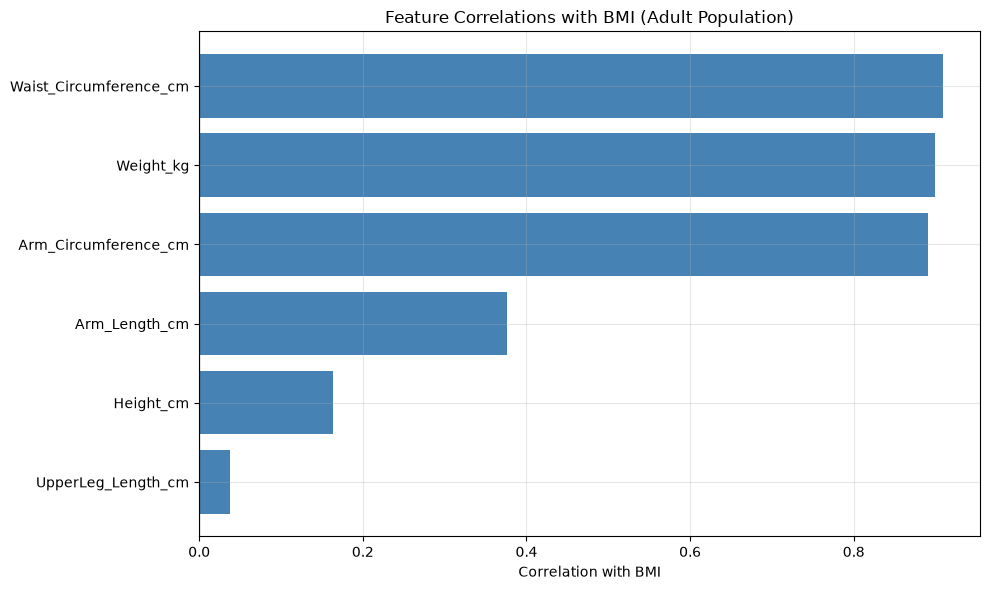

In [33]:
# ─────────────────────────────────────────────────
# STEP 7: Bar chart — BMI correlations
# ─────────────────────────────────────────────────
plt.figure(figsize=(10, 6))
colors = ['steelblue' if v > 0 else 'indianred' for v in bmi_corr.values]
plt.barh(range(len(bmi_corr)), bmi_corr.values, color=colors)
plt.yticks(range(len(bmi_corr)), bmi_corr.index)
plt.xlabel('Correlation with BMI')
plt.title('Feature Correlations with BMI (Adult Population)')
plt.axvline(0, color='black', linewidth=0.8)
plt.gca().invert_yaxis()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### MODEL

In [34]:
# ═══════════════════════════════════════════════════
# FEATURE SELECTION FOR CLUSTERING
# ═══════════════════════════════════════════════════

features_for_clustering = [
    'Waist_Circumference_cm',   # body size
    'Height_cm',                 # vertical proportion
    'Arm_Length_cm',             # horizontal proportion
    'UpperLeg_Length_cm',        # lower body proportion
]

X_cluster = df_adults[features_for_clustering].copy()
print("Clustering features:", features_for_clustering)
print("Shape:", X_cluster.shape)

Clustering features: ['Waist_Circumference_cm', 'Height_cm', 'Arm_Length_cm', 'UpperLeg_Length_cm']
Shape: (51605, 4)


In [35]:
# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

In [36]:
# Elbow + silhouette
inertias = []
silhouettes = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    print(f"K={k}: inertia={km.inertia_:.0f}, silhouette={silhouettes[-1]:.3f}")


K=2: inertia=118007, silhouette=0.351
K=3: inertia=93097, silhouette=0.271
K=4: inertia=74985, silhouette=0.279
K=5: inertia=65371, silhouette=0.264
K=6: inertia=57719, silhouette=0.251
K=7: inertia=52629, silhouette=0.248
K=8: inertia=48595, silhouette=0.234
K=9: inertia=45107, silhouette=0.236
K=10: inertia=42662, silhouette=0.230


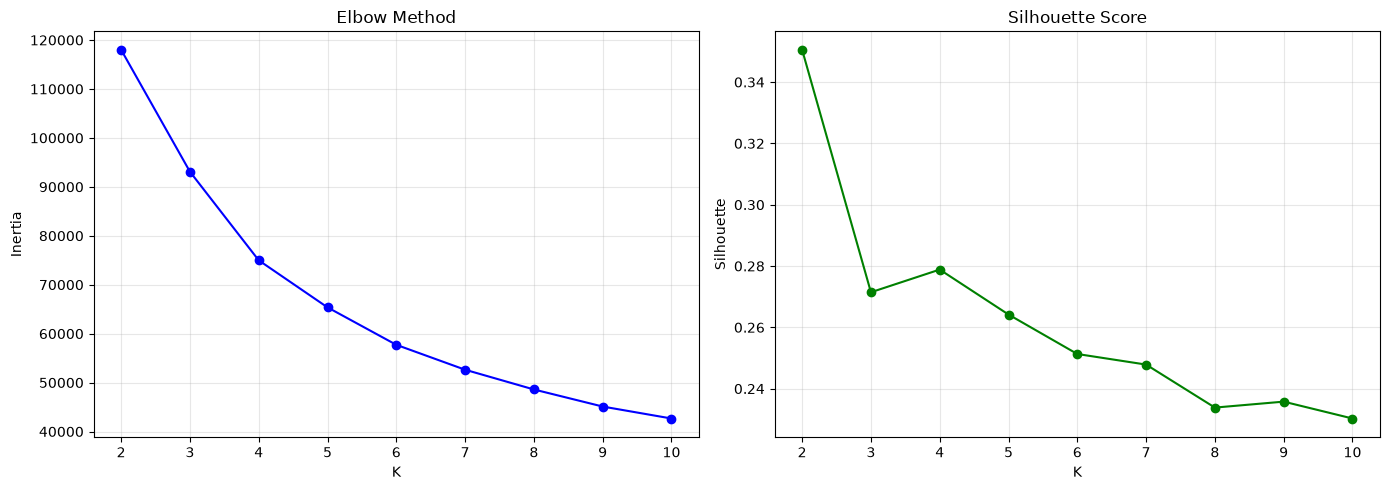

In [37]:
# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertias, 'bo-')
axes[0].set_xlabel('K'); axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method'); axes[0].grid(alpha=0.3)

axes[1].plot(K_range, silhouettes, 'go-')
axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhouette')
axes[1].set_title('Silhouette Score'); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
# making model using k means.

K = 4
km = KMeans(n_clusters=K, random_state=42, n_init=10)
df_adults['cluster'] = km.fit_predict(X_scaled)

print("Cluster sizes:")
print(df_adults['cluster'].value_counts().sort_index())

print("\nCluster profiles:")
cluster_summary = df_adults.groupby('cluster')[features_for_clustering].mean().round(2)
print(cluster_summary)

Cluster sizes:
cluster
0    11996
1    13829
2     9917
3    15863
Name: count, dtype: int64

Cluster profiles:
         Waist_Circumference_cm  Height_cm  Arm_Length_cm  UpperLeg_Length_cm
cluster                                                                      
0                        109.78     161.59          36.66               36.61
1                        103.32     177.53          40.08               43.09
2                         77.55     148.76          32.02               34.69
3                         82.50     165.51          36.12               39.92


In [39]:
# cluster stats.

print("Current cluster stats: ")
cluster_stats = df_adults.groupby('cluster')[
    ['Waist_Circumference_cm', 'Height_cm', 'Arm_Length_cm', 'UpperLeg_Length_cm']
].mean()

print("Cluster stats: ")
print(cluster_stats.round(1))

# Rule based mapping.
def name_cluster(row):
    waist = row['Waist_Circumference_cm']
    height = row['Height_cm']

    if height < 155:
        return 'Petite'
    elif height > 175:
        return 'Tall'
    elif waist > 105:
        return 'Broad'
    else:
        return 'Average'

cluster_stats['body_type'] = cluster_stats.apply(name_cluster, axis= 1)
cluster_names = cluster_stats['body_type'].to_dict()

print("\nMapping:")
for cid, name in cluster_names.items():
    print(f"    Cluster {cid} -> {name}")

# Apply names to dataset
df_adults['body_type'] = df_adults['cluster'].map(cluster_names)

print("\n Body Type didtribution: ")
print(df_adults['body_type'].value_counts())

Current cluster stats: 


Cluster stats: 
         Waist_Circumference_cm  Height_cm  Arm_Length_cm  UpperLeg_Length_cm
cluster                                                                      
0                         109.8      161.6           36.7                36.6
1                         103.3      177.5           40.1                43.1
2                          77.5      148.8           32.0                34.7
3                          82.5      165.5           36.1                39.9

Mapping:
    Cluster 0 -> Broad
    Cluster 1 -> Tall
    Cluster 2 -> Petite
    Cluster 3 -> Average

 Body Type didtribution: 
body_type
Average    15863
Tall       13829
Broad      11996
Petite      9917
Name: count, dtype: int64


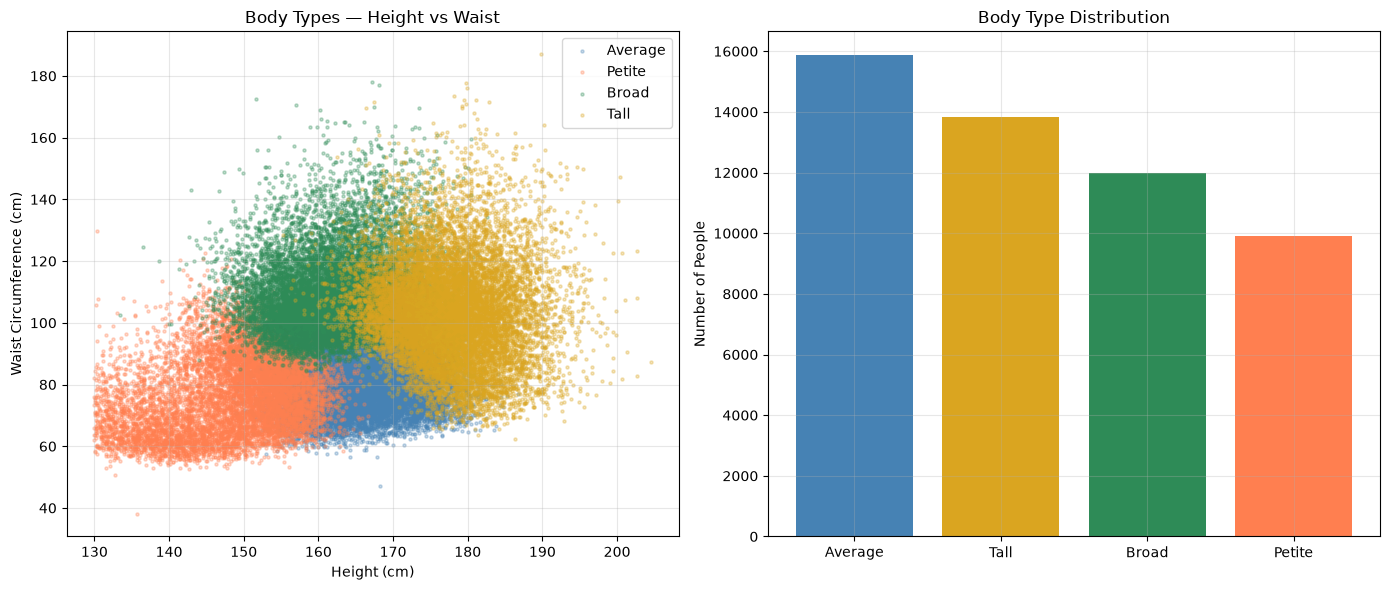

In [40]:
# plotiing.

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Height vs Waist
colors = {'Average': 'steelblue', 'Petite': 'coral', 
          'Broad': 'seagreen', 'Tall': 'goldenrod'}

for body_type, color in colors.items():
    subset = df_adults[df_adults['body_type'] == body_type]
    axes[0].scatter(subset['Height_cm'], subset['Waist_Circumference_cm'],
                    alpha=0.3, s=5, c=color, label=body_type)

axes[0].set_xlabel('Height (cm)')
axes[0].set_ylabel('Waist Circumference (cm)')
axes[0].set_title('Body Types — Height vs Waist')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Cluster sizes
body_counts = df_adults['body_type'].value_counts()
axes[1].bar(body_counts.index, body_counts.values, 
            color=[colors[k] for k in body_counts.index])
axes[1].set_ylabel('Number of People')
axes[1].set_title('Body Type Distribution')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('body_type_visualization.png', dpi= 300, bbox_inches= 'tight')
plt.show()

#### **SAVING MODEL**

In [ ]:
cluster_names = {
    0: 'Broad',
    1: 'Tall',
    2: 'Petite',
    3: 'Average'
}

joblib.dump(cluster_names, 'bodytype_labels.pkl')
joblib.dump(scaler, 'bodytype_scaler.pkl')
joblib.dump(km, 'bodytype_kmeans.pkl')

df_adults.to_csv('data/nhanes_bodytypes.csv', index= False)

print('Saved:')
print("Saved: bodytype_labels.pkl")
print("-bodytype_scaler.pkl ")
print("-bodytype_kmeans.pkl ")
print("-nhanes_bodytypes.csv ")
print("\nShape:", df_adults.shape)
print("\nBody Types:")
print(df_adults['body_type'].value_counts())

Saved:
Saved: bodytype_labels.pkl
-bodytype_scaler.pkl 
-bodytype_kmeans.pkl 
-nhanes_bodytypes.csv 

Shape: (51605, 9)

Body Types:
body_type
Average    15863
Tall       13829
Broad      11996
Petite      9917
Name: count, dtype: int64


#### **PREDICTIONS**

In [42]:
# ═══════════════════════════════════════════════════
# BODY TYPE PREDICTION FUNCTION
# ═══════════════════════════════════════════════════

def predict_body_type(height_cm, waist_cm, arm_length_cm, leg_length_cm):
    """
    Predict body type for a new person.
    
    Args:
        height_cm: Height in centimeters
        waist_cm: Waist circumference in centimeters
        arm_length_cm: Arm length in centimeters
        leg_length_cm: Upper leg length in centimeters
    
    Returns:
        dict with body type and distance to each cluster center
    """
    
    # Build input row
    row = pd.DataFrame([{
        'Waist_Circumference_cm': waist_cm,
        'Height_cm': height_cm,
        'Arm_Length_cm': arm_length_cm,
        'UpperLeg_Length_cm': leg_length_cm,
    }])
    
    # Scale using the SAME scaler from training
    row_scaled = scaler.transform(row)
    
    # Predict cluster
    cluster = km.predict(row_scaled)[0]
    
    # Get distances to all cluster centers
    distances = km.transform(row_scaled)[0]
    
    body_type = cluster_names[cluster]
    
    return {
        'body_type': body_type,
        'cluster_id': int(cluster),
        'distances_to_centers': {
            cluster_names[i]: round(float(d), 2) 
            for i, d in enumerate(distances)
        }
    }

In [43]:
# ─── TEST IT ───
print("Test 1 — Average person (165cm, 82cm waist, 36cm arm, 40cm leg):")
print(predict_body_type(165, 82, 36, 40))
print()

print("Test 2 — Petite person (150cm, 78cm waist, 32cm arm, 35cm leg):")
print(predict_body_type(150, 78, 32, 35))
print()

print("Test 3 — Tall person (178cm, 103cm waist, 40cm arm, 43cm leg):")
print(predict_body_type(178, 103, 40, 43))
print()

print("Test 4 — Broad person (162cm, 110cm waist, 37cm arm, 37cm leg):")
print(predict_body_type(162, 110, 37, 37))

Test 1 — Average person (165cm, 82cm waist, 36cm arm, 40cm leg):
{'body_type': 'Average', 'cluster_id': 3, 'distances_to_centers': {'Broad': 1.78, 'Tall': 2.17, 'Petite': 2.32, 'Average': 0.06}}

Test 2 — Petite person (150cm, 78cm waist, 32cm arm, 35cm leg):
{'body_type': 'Petite', 'cluster_id': 2, 'distances_to_centers': {'Broad': 2.5, 'Tall': 4.24, 'Petite': 0.14, 'Average': 2.24}}

Test 3 — Tall person (178cm, 103cm waist, 40cm arm, 43cm leg):
{'body_type': 'Tall', 'cluster_id': 1, 'distances_to_centers': {'Broad': 2.42, 'Tall': 0.05, 'Petite': 4.34, 'Average': 2.12}}

Test 4 — Broad person (162cm, 110cm waist, 37cm arm, 37cm leg):
{'body_type': 'Broad', 'cluster_id': 0, 'distances_to_centers': {'Broad': 0.15, 'Tall': 2.28, 'Petite': 2.68, 'Average': 1.73}}
